# 02 - Feature Engineering, Model Selection & Tuning

This notebook documents *why* the final model was chosen:

1. the preprocessing pipeline (scaling, encoding, engineered features),
2. an un-tuned baseline comparison of several model families,
3. analysis of the hyper-parameter search tracked in **MLflow** (produced by `python -m heart_disease.train`, which also runs in CI),
4. evaluation of the champion on the held-out test set, incl. decision-threshold analysis.

In [1]:
%matplotlib inline
import json

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from heart_disease import config
from heart_disease.data import load_clean, split_features_target
from heart_disease.evaluate import compute_metrics
from heart_disease.features import build_pipeline, transformed_feature_names
from heart_disease.predict import load_model

set_config(display="diagram")
sns.set_theme(style="whitegrid")

## 1. Train / test split
A stratified 80/20 split with a fixed seed. The test set is **only** used for the final evaluation - all model selection happens with 5-fold stratified cross-validation on the training split.

In [2]:
df = load_clean()
X, y = split_features_target(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=config.TEST_SIZE, stratify=y, random_state=config.RANDOM_STATE
)
print(f"train={X_train.shape}, test={X_test.shape}, positive rate train={y_train.mean():.2f} test={y_test.mean():.2f}")

train=(242, 13), test=(61, 13), positive rate train=0.46 test=0.46


## 2. Preprocessing pipeline
`ClinicalFeatureAdder` -> `ColumnTransformer`:
* numeric (+ engineered) -> median imputation -> `StandardScaler`
* binary -> most-frequent imputation
* nominal (`cp`, `restecg`, `slope`, `thal`) -> most-frequent imputation -> `OneHotEncoder(handle_unknown="ignore")`

The whole pipeline incl. the classifier is serialised as one object, so the API applies identical transformations.

In [3]:
pipe = build_pipeline(LogisticRegression(max_iter=2000)).fit(X_train, y_train)
names = transformed_feature_names(pipe)
print(len(names), "model inputs:", names)
pipe

24 model inputs: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'hr_achievement', 'risk_flag_count', 'sex', 'fbs', 'exang', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


Pipeline(steps=[('features', ClinicalFeatureAdder()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak', 'ca',
                                                   'hr_achievement',
                                                   'risk_flag_count']),
                                                 ('bin',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['sex', 'fbs', 'exang']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['cp', 'restecg', 'slope',
                                                   'thal'])],
                                   verbose_feature_names_out=False)),
                ('clf', LogisticRegression(max_iter=2000))])

## 3. Baseline comparison (default hyper-parameters, 5-fold CV)
A majority-class dummy gives the floor. Linear, kernel, neighbour and tree-ensemble families are compared with the same pipeline.

In [4]:
cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
baselines = {
    "dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "logistic_regression": LogisticRegression(max_iter=2000),
    "svc_rbf": SVC(probability=True, random_state=config.RANDOM_STATE),
    "knn_15": KNeighborsClassifier(n_neighbors=15),
    "random_forest": RandomForestClassifier(random_state=config.RANDOM_STATE),
    "gradient_boosting": GradientBoostingClassifier(random_state=config.RANDOM_STATE),
}
rows = {}
for name, est in baselines.items():
    scores = cross_validate(build_pipeline(est), X_train, y_train, cv=cv,
                            scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    rows[name] = {m: f"{scores[f'test_{m}'].mean():.3f} +/- {scores[f'test_{m}'].std():.3f}"
                  for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
pd.DataFrame(rows).T

C:\MtechBitsPilani\Sem3_MLOps_Assignment1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\MtechBitsPilani\Sem3_MLOps_Assignment1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\MtechBitsPilani\Sem3_MLOps_Assignment1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

C:\MtechBitsPilani\Sem3_MLOps_Assignment1\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\MtechBitsPilani\Sem3_MLOps_Assignment1\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\MtechBitsPilani\Sem3_MLOps_Assignment1\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\MtechBitsPilani\Sem3_MLOps_Assignment1\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning:

,accuracy,precision,recall,f1,roc_auc
dummy (majority),0.541 +/- 0.006,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000
logistic_regression,0.835 +/- 0.027,0.861 +/- 0.076,0.774 +/- 0.059,0.811 +/- 0.029,0.900 +/- 0.026
svc_rbf,0.797 +/- 0.032,0.823 +/- 0.094,0.729 +/- 0.052,0.768 +/- 0.028,0.873 +/- 0.014
knn_15,0.785 +/- 0.038,0.824 +/- 0.079,0.684 +/- 0.033,0.745 +/- 0.037,0.857 +/- 0.022
random_forest,0.797 +/- 0.032,0.806 +/- 0.042,0.738 +/- 0.080,0.767 +/- 0.044,0.875 +/- 0.037
gradient_boosting,0.802 +/- 0.035,0.800 +/- 0.040,0.757 +/- 0.062,0.777 +/- 0.046,0.865 +/- 0.020


**Observation.** All real models clearly beat the dummy. The linear model is already competitive with the ensembles: with ~240 training rows and mostly monotonic relationships seen in the EDA, a well-regularised linear model is hard to beat, while forests/boosting have higher variance. Logistic Regression, Random Forest and Gradient Boosting were carried forward to tuning (one linear, one bagging and one boosting family); SVC/KNN offered no gain and are less interpretable.

## 4. Hyper-parameter tuning - results from MLflow
`heart_disease.train` runs `GridSearchCV` (5-fold stratified CV, refit on ROC-AUC) for each family and logs:
* a **parent run** per family: best params, CV mean/std of all metrics, test metrics, confusion matrix, ROC/PR curves, feature importance, CV table, serialised model (+ signature & input example);
* a **nested run per grid candidate** (params + CV metrics) - 64 candidates in total;
* a **model-selection run** comparing the families, and the champion is registered as `heart-disease-classifier@champion`.

In [5]:
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT])
print("Total runs in experiment:", len(runs))
parents = runs[runs["tags.run_type"] == "tuning"].drop_duplicates("tags.model_family")
cols = ["tags.model_family", "metrics.cv_roc_auc_mean", "metrics.cv_roc_auc_std", "metrics.cv_accuracy_mean",
        "metrics.cv_recall_mean", "metrics.test_roc_auc", "metrics.test_accuracy", "metrics.test_recall"]
parents[cols].set_index("tags.model_family").sort_values("metrics.cv_roc_auc_mean", ascending=False).round(4)

Total runs in experiment: 68


,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,metrics.cv_accuracy_mean,metrics.cv_recall_mean,metrics.test_roc_auc,metrics.test_accuracy,metrics.test_recall
tags.model_family,,,,,,,
logistic_regression,0.9030,0.0244,0.8426,0.8099,0.9567,0.8689,0.9286
random_forest,0.8904,0.0250,0.8262,0.7644,0.9437,0.8852,0.8929
gradient_boosting,0.8790,0.0274,0.8137,0.7739,0.9545,0.9016,0.9286


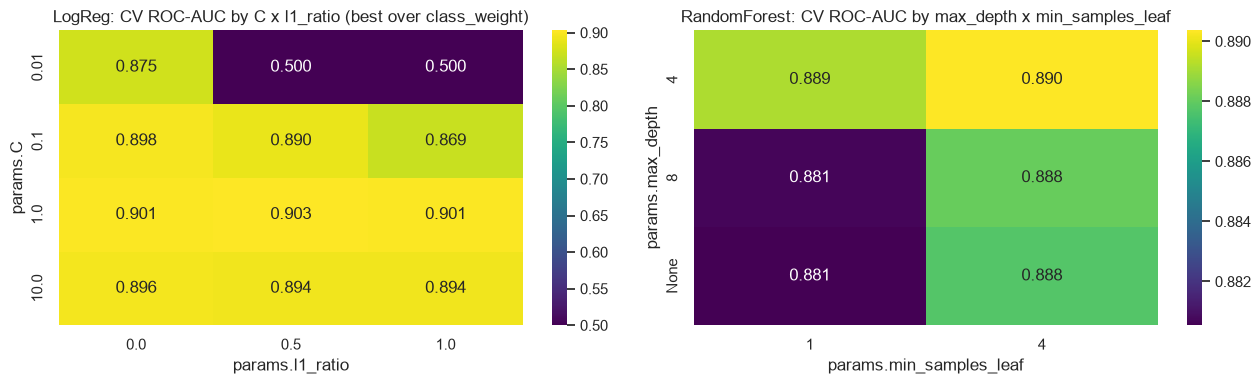

In [6]:
cands = runs[runs["tags.run_type"] == "candidate"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lr = cands[cands["tags.model_family"] == "logistic_regression"]
lr_piv = lr.pivot_table(index="params.C", columns="params.l1_ratio", values="metrics.cv_roc_auc_mean", aggfunc="max")
sns.heatmap(lr_piv, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set_title("LogReg: CV ROC-AUC by C x l1_ratio (best over class_weight)")
rf = cands[cands["tags.model_family"] == "random_forest"]
rf_piv = rf.pivot_table(index="params.max_depth", columns="params.min_samples_leaf", values="metrics.cv_roc_auc_mean", aggfunc="max")
sns.heatmap(rf_piv, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("RandomForest: CV ROC-AUC by max_depth x min_samples_leaf")
plt.tight_layout()

**Tuning insights.** Very strong regularisation (`C=0.01`) collapses the logistic model towards predicting one class; moderate `C` is best and the L1/L2 mix matters little. Random forests benefit from shallow trees / larger leaves, which again indicates that variance, not bias, is the main risk on this small dataset.

**Selection rule:** highest mean CV ROC-AUC (threshold-independent, robust to the mild imbalance). The test set was *not* used for selection.

## 5. Champion evaluation on the held-out test set

In [7]:
meta = json.loads(config.MODEL_METADATA_FILE.read_text())
print("Champion:", meta["model_name"], meta["best_params"])
model = load_model()
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["no disease", "disease"]))
pd.Series(compute_metrics(y_test, proba)).round(4).to_frame("test")

Champion: logistic_regression {'C': '1.0', 'class_weight': 'balanced', 'l1_ratio': '0.5'}
              precision    recall  f1-score   support

  no disease       0.93      0.82      0.87        33
     disease       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



,test
accuracy,0.8689
precision,0.8125
recall,0.9286
f1,0.8667
roc_auc,0.9567
avg_precision,0.9395


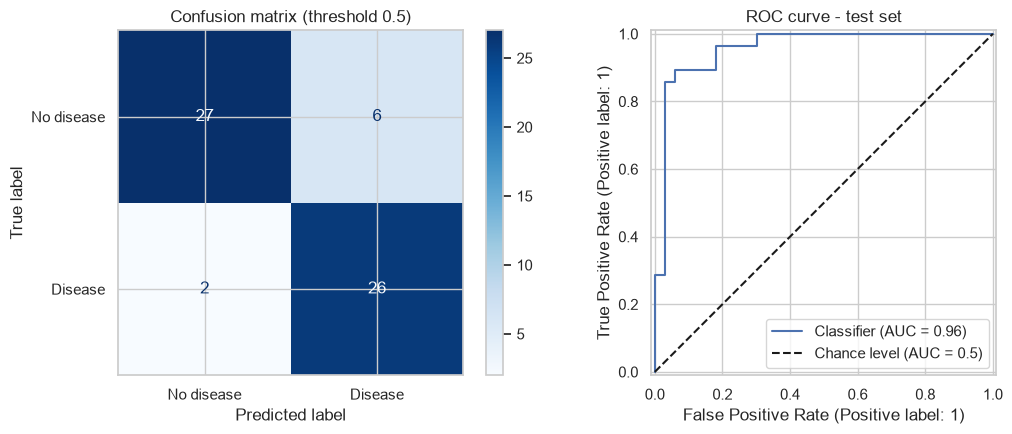

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No disease", "Disease"], cmap="Blues", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], plot_chance_level=True)
axes[0].set_title("Confusion matrix (threshold 0.5)")
axes[1].set_title("ROC curve - test set")
plt.tight_layout()

## 6. Decision threshold analysis
For a screening use case a missed disease (false negative) is costlier than a false alarm. The table shows the precision/recall trade-off; the API currently uses 0.5 (stored in `models/metadata.json` as `decision_threshold`, so it can be changed without retraining).

In [9]:
pd.DataFrame({t: compute_metrics(y_test, proba, threshold=t) for t in [0.3, 0.4, 0.5, 0.6, 0.7]}).T[
    ["accuracy", "precision", "recall", "f1"]].round(3).rename_axis("threshold")

,accuracy,precision,recall,f1
threshold,,,,
0.3,0.820,0.730,0.964,0.831
0.4,0.852,0.771,0.964,0.857
0.5,0.869,0.812,0.929,0.867
0.6,0.869,0.833,0.893,0.862
0.7,0.902,0.893,0.893,0.893


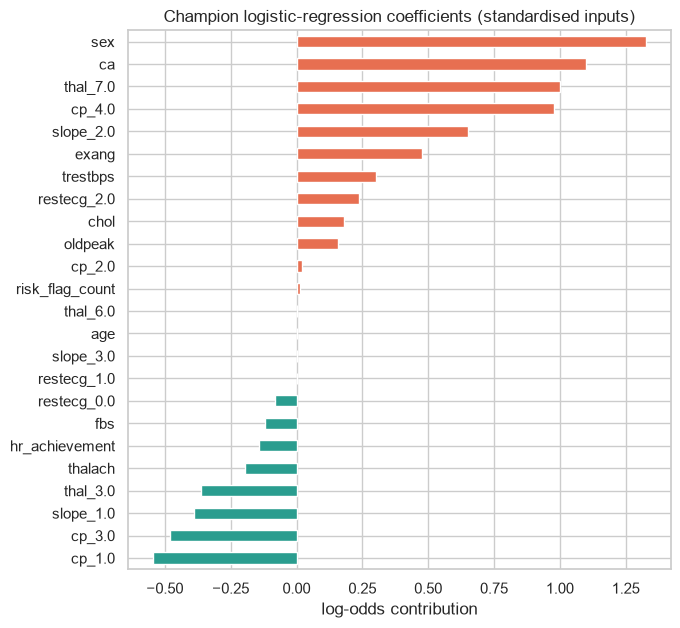

In [10]:
clf = model.named_steps["clf"]
coefs = pd.Series(clf.coef_.ravel(), index=transformed_feature_names(model)).sort_values()
ax = coefs.plot.barh(figsize=(7, 7), color=["#2a9d8f" if c < 0 else "#e76f51" for c in coefs])
ax.set_title("Champion logistic-regression coefficients (standardised inputs)")
ax.set_xlabel("log-odds contribution");

## 7. Conclusion
* **Chosen model:** regularised Logistic Regression inside the full preprocessing pipeline - best CV ROC-AUC, lowest variance across folds, and directly interpretable coefficients (important for a clinical setting).
* The coefficients agree with the EDA: asymptomatic chest pain, reversible thallium defect, more coloured vessels and ST depression increase risk; a high heart-rate achievement decreases it.
* Artefacts: `models/model.joblib` (+ `metadata.json`) for serving and `heart-disease-classifier@champion` in the MLflow registry.